<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/BAB9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

In [2]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [3]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

In [4]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))

for nama, model in [
    ("Decision Tree Tunggal", tree_tunggal),
    ("Random Forest", rf),
    ("AdaBoost", ada),
    ("Gradient Boosting", gb),
]:
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Test = {acc:.3f}")

OOB Score Random Forest: 0.979
Decision Tree Tunggal: Akurasi Test = 0.944
Random Forest: Akurasi Test = 1.000
AdaBoost: Akurasi Test = 0.917
Gradient Boosting: Akurasi Test = 0.944


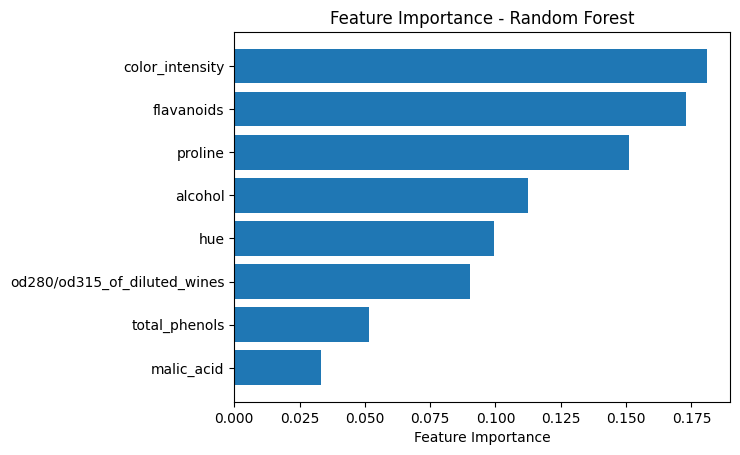

In [5]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:8]
plt.barh([data.feature_names[i] for i in idx][::-1], importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.show()